# Mini-Projet : Implémentation, analyse et amélioration d'un MLP sous PyTorch
Auteur : EZZAHRAOUI El-Mehdi

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import os

os.makedirs('../figures', exist_ok=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Utilisation du device :', device)

Utilisation du device : cpu


## Chargement des données Fashion-MNIST

In [6]:
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.FashionMNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='../data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

## Implémentation From Scratch (Partie II)

In [7]:
class MLPFromScratch(nn.Module):
    def __init__(self, num_inputs=784, num_hiddens=256, num_outputs=10):
        super().__init__()
        self.W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens) * 0.01)
        self.b1 = nn.Parameter(torch.zeros(num_hiddens))
        self.W2 = nn.Parameter(torch.randn(num_hiddens, num_outputs) * 0.01)
        self.b2 = nn.Parameter(torch.zeros(num_outputs))

    def relu(self, X):
        return torch.max(X, torch.tensor(0.0))

    def forward(self, X):
        X = X.reshape((-1, 784))
        H = self.relu(torch.matmul(X, self.W1) + self.b1)
        return torch.matmul(H, self.W2) + self.b2

## Implémentation Concise avec PyTorch (Partie III)

In [8]:
class ConciseMLP(nn.Module):
    def __init__(self, num_inputs=784, num_hiddens=256, num_outputs=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(num_inputs, num_hiddens),
            nn.ReLU(),
            nn.Linear(num_hiddens, num_outputs)
        )

    def forward(self, X):
        return self.net(X)

model = ConciseMLP().to(device)
print(model)
print('Nombre total de paramètres :', sum(p.numel() for p in model.parameters() if p.requires_grad))

ConciseMLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)
Nombre total de paramètres : 203530


## Partie IV : Inspection interne du modèle
Dans cette partie, nous inspectons les dimensions des couches, les poids, les biais, les gradients, et nous vérifions le fonctionnement d'autograd.

In [9]:
# 1. Afficher les dimensions avant et après le premier forward
for X_batch, y_batch in train_loader:
    X_batch = X_batch.to(device)
    print("Shape des images d'entrée (batch) :", X_batch.shape)
    flattened = nn.Flatten()(X_batch)
    print("Shape après aplatissement (Flatten) :", flattened.shape)
    output = model(X_batch)
    print("Shape de la sortie du modèle (logits) :", output.shape)
    break

# 2. Extraire quelques poids, biais et observer les gradients via autograd
print("\n--- Inspection des poids et biais ---")
print("Shape des poids de la 1ère couche linéaire :", model.net[1].weight.shape)
print("Exemple de poids (w1) :\n", model.net[1].weight[:2, :5])
print("Exemple de biais (b1) :\n", model.net[1].bias[:5])

# Calcul d'une perte factice et rétropropagation pour générer les gradients
sample_loss = nn.CrossEntropyLoss()(output, y_batch.to(device))
sample_loss.backward()

print("\n--- Inspection des gradients après backward() ---")
print("Gradient des poids de la 1ère couche :\n", model.net[1].weight.grad[:2, :5])

Shape des images d'entrée (batch) : torch.Size([256, 1, 28, 28])
Shape après aplatissement (Flatten) : torch.Size([256, 784])
Shape de la sortie du modèle (logits) : torch.Size([256, 10])

--- Inspection des poids et biais ---
Shape des poids de la 1ère couche linéaire : torch.Size([256, 784])
Exemple de poids (w1) :
 tensor([[-0.0292,  0.0196, -0.0210, -0.0244,  0.0148],
        [ 0.0196, -0.0047,  0.0145, -0.0055, -0.0343]],
       grad_fn=<SliceBackward0>)
Exemple de biais (b1) :
 tensor([ 0.0012, -0.0130, -0.0309, -0.0254, -0.0028], grad_fn=<SliceBackward0>)

--- Inspection des gradients après backward() ---
Gradient des poids de la 1ère couche :
 tensor([[0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0.]])


## Partie V : Procédure d'Entraînement et Étude Expérimentale
Nous mettons en place une fonction d'entraînement complète pour suivre l'évolution de la perte (loss) et de la précision (accuracy) sur les ensembles d'entraînement et de test.

In [10]:
import matplotlib.pyplot as plt

def run_experiment(net, train_loader, test_loader, epochs=5, lr=0.1):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr)
    
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    
    for epoch in range(epochs):
        net.train()
        train_loss, correct, total = 0, 0, 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = net(X)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * X.size(0)
            _, predicted = outputs.max(1)
            total += y.size(0)
            correct += predicted.eq(y).sum().item()
        
        epoch_loss = train_loss / total
        epoch_acc = correct / total
        history['train_loss'].append(epoch_loss)
        history['train_acc'].append(epoch_acc)
        
        # Évaluation sur le test
        net.eval()
        test_loss, test_correct, test_total = 0, 0, 0
        with torch.no_grad():
            for X, y in test_loader:
                X, y = X.to(device), y.to(device)
                outputs = net(X)
                loss = criterion(outputs, y)
                test_loss += loss.item() * X.size(0)
                _, predicted = outputs.max(1)
                test_total += y.size(0)
                test_correct += predicted.eq(y).sum().item()
        
        history['test_loss'].append(test_loss / test_total)
        history['test_acc'].append(test_correct / test_total)
        
        print(f"Époque [{epoch+1}/{epochs}] - Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_acc*100:.2f}% | Test Loss: {history['test_loss'][-1]:.4f}, Test Acc: {history['test_acc'][-1]*100:.2f}%")
        
    return history

# Instanciation d'un nouveau modèle propre pour l'entraînement
model_exp = ConciseMLP().to(device)
history_base = run_experiment(model_exp, train_loader, test_loader, epochs=10, lr=0.1)

Époque [1/10] - Train Loss: 0.8682, Train Acc: 71.37% | Test Loss: 0.7075, Test Acc: 74.82%
Époque [2/10] - Train Loss: 0.5572, Train Acc: 80.70% | Test Loss: 0.5525, Test Acc: 80.86%
Époque [3/10] - Train Loss: 0.4984, Train Acc: 82.46% | Test Loss: 0.5296, Test Acc: 81.05%
Époque [4/10] - Train Loss: 0.4601, Train Acc: 83.94% | Test Loss: 0.4837, Test Acc: 82.89%
Époque [5/10] - Train Loss: 0.4374, Train Acc: 84.72% | Test Loss: 0.5208, Test Acc: 81.46%
Époque [6/10] - Train Loss: 0.4218, Train Acc: 85.22% | Test Loss: 0.4590, Test Acc: 83.91%
Époque [7/10] - Train Loss: 0.4034, Train Acc: 85.84% | Test Loss: 0.4710, Test Acc: 83.54%
Époque [8/10] - Train Loss: 0.3927, Train Acc: 86.13% | Test Loss: 0.4543, Test Acc: 83.51%
Époque [9/10] - Train Loss: 0.3821, Train Acc: 86.56% | Test Loss: 0.4374, Test Acc: 84.44%
Époque [10/10] - Train Loss: 0.3749, Train Acc: 86.79% | Test Loss: 0.4261, Test Acc: 84.44%


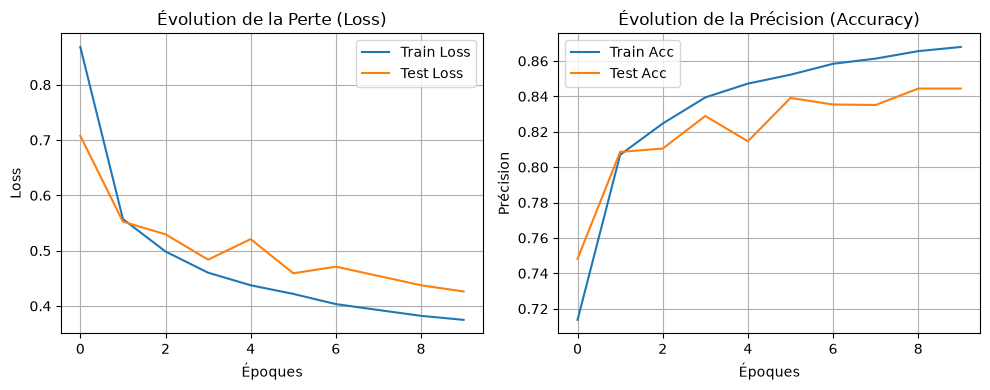

Graphique sauvegardé dans ../figures/mlp_baseline_curves.png


In [11]:
plt.figure(figsize=(10, 4))

# Courbe de perte (Loss)
plt.subplot(1, 2, 1)
plt.plot(history_base['train_loss'], label='Train Loss')
plt.plot(history_base['test_loss'], label='Test Loss')
plt.title('Évolution de la Perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Courbe de précision (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history_base['train_acc'], label='Train Acc')
plt.plot(history_base['test_acc'], label='Test Acc')
plt.title('Évolution de la Précision (Accuracy)')
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('../figures/mlp_baseline_curves.png')
plt.show()
print("Graphique sauvegardé dans ../figures/mlp_baseline_curves.png")